# 01 – Mô tả dữ liệu, kiểm tra chất lượng và làm sạch

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import CUTOFF, FIGURES_DIR, TABLES_DIR, SEED
from src.data_loader import load_raw
from src.cleaning import clean_transactions, save_cleaning_log, NON_PRODUCT_CODES

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIGURES_DIR / name, bbox_inches="tight", dpi=150)

## A. Mô tả dataset

- **Nguồn:** UCI Machine Learning Repository – *Online Retail* (Chen, 2015): https://archive.ics.uci.edu/dataset/352/online+retail
- Dữ liệu giao dịch của một công ty bán lẻ quà tặng trực tuyến đặt tại Anh, nhiều khách hàng là nhà bán sỉ.
- Chưa có biến mục tiêu (bài toán gom cụm, học không giám sát).

In [2]:
df = load_raw()
print("Số mẫu (dòng):", f"{len(df):,}")
print("Số thuộc tính (cột):", df.shape[1])
print()
meaning = {
    "InvoiceNo": "Mã hóa đơn (6 chữ số); bắt đầu bằng 'C' là hóa đơn hủy/trả hàng",
    "StockCode": "Mã sản phẩm (thường 5 chữ số + chữ cái tùy chọn)",
    "Description": "Tên/mô tả sản phẩm",
    "Quantity": "Số lượng sản phẩm trên dòng (âm với hóa đơn hủy)",
    "InvoiceDate": "Thời điểm lập hóa đơn",
    "UnitPrice": "Đơn giá (bảng Anh, GBP)",
    "CustomerID": "Mã khách hàng (5 chữ số), có thể thiếu",
    "Country": "Quốc gia của khách hàng",
}
schema = pd.DataFrame({
    "kiểu dữ liệu": df.dtypes.astype(str),
    "không thiếu": df.notna().sum(),
    "số giá trị khác nhau": df.nunique(),
    "ý nghĩa": pd.Series(meaning),
})
schema

Số mẫu (dòng): 541,909
Số thuộc tính (cột): 8



,kiểu dữ liệu,không thiếu,số giá trị khác nhau,ý nghĩa
InvoiceNo,str,541909,25900,Mã hóa đơn (6 chữ số); bắt đầu bằng 'C' là hóa...
StockCode,str,541909,4070,Mã sản phẩm (thường 5 chữ số + chữ cái tùy chọn)
Description,object,540455,4223,Tên/mô tả sản phẩm
Quantity,int64,541909,722,Số lượng sản phẩm trên dòng (âm với hóa đơn hủy)
InvoiceDate,datetime64[us],541909,23260,Thời điểm lập hóa đơn
UnitPrice,float64,541909,1630,"Đơn giá (bảng Anh, GBP)"
CustomerID,Int64,406829,4372,"Mã khách hàng (5 chữ số), có thể thiếu"
Country,str,541909,38,Quốc gia của khách hàng


In [3]:
print("5 dòng ví dụ:")
df.head(5)

5 dòng ví dụ:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [4]:
print("Khoảng thời gian:", df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())
summary = pd.Series({
    "Số hóa đơn (InvoiceNo khác nhau)": df["InvoiceNo"].nunique(),
    "Số khách hàng (CustomerID khác nhau, không tính thiếu)": df["CustomerID"].nunique(),
    "Số mã sản phẩm (StockCode khác nhau)": df["StockCode"].nunique(),
    "Số quốc gia": df["Country"].nunique(),
})
summary.to_frame("giá trị")

Khoảng thời gian: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00


,giá trị
Số hóa đơn (InvoiceNo khác nhau),25900
"Số khách hàng (CustomerID khác nhau, không tính thiếu)",4372
Số mã sản phẩm (StockCode khác nhau),4070
Số quốc gia,38


## B. Kiểm tra chất lượng và quyết định xử lý

Mỗi mục dưới đây trả lời: *vấn đề là gì → ảnh hưởng bao nhiêu dòng → quyết định → lý do*. Các quyết định đều là **quy tắc logic**, không dựa vào ngưỡng thống kê tính từ dữ liệu, nên không dùng thông tin của giai đoạn kiểm chứng (xem mục D).

### B1. Dữ liệu thiếu

,số dòng thiếu,% thiếu
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


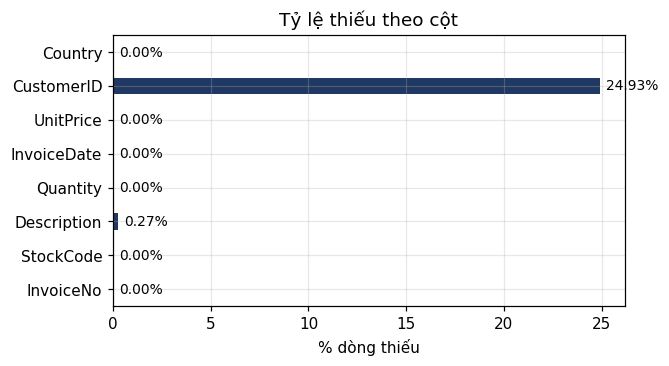

Dòng thiếu Description: 1454
 - trong đó có CustomerID: 0
 - trong đó UnitPrice == 0: 1454


In [5]:
miss = pd.DataFrame({"số dòng thiếu": df.isna().sum(), "% thiếu": df.isna().mean() * 100})
display(miss)

fig, ax = plt.subplots(figsize=(6, 3.2))
miss["% thiếu"].plot.barh(ax=ax, color="#1F3864")
ax.set_xlabel("% dòng thiếu"); ax.set_title("Tỷ lệ thiếu theo cột")
for i, v in enumerate(miss["% thiếu"]):
    ax.text(v + 0.3, i, f"{v:.2f}%", va="center", fontsize=9)
savefig("eda_missing_by_column.png"); plt.show()

desc_na = df[df["Description"].isna()]
print("Dòng thiếu Description:", len(desc_na))
print(" - trong đó có CustomerID:", desc_na["CustomerID"].notna().sum())
print(" - trong đó UnitPrice == 0:", (desc_na["UnitPrice"] == 0).sum())

**Nhận xét và quyết định**

- `CustomerID` thiếu khoảng 24,9% số dòng. Không có mã khách thì không thể gom giao dịch theo khách, nên **loại các dòng này khỏi bài toán phân khúc** (đây là hạn chế của dữ liệu, sẽ ghi vào chương hạn chế).
- `Description` thiếu 1.454 dòng; toàn bộ các dòng này đồng thời thiếu `CustomerID` và có `UnitPrice = 0`, tức là các điều chỉnh kho, không phải giao dịch bán. Chúng bị loại cùng bước loại thiếu `CustomerID`, không cần xử lý riêng.

### B2. Dòng trùng lặp

In [6]:
dup_mask = df.duplicated(keep="first")
print("Số dòng trùng lặp hoàn toàn (so với dòng xuất hiện trước):", dup_mask.sum())
print("  % tổng số dòng:", f"{dup_mask.mean()*100:.2f}%")
print("  trong đó có CustomerID:", df.loc[dup_mask, "CustomerID"].notna().sum())
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6)

Số dòng trùng lặp hoàn toàn (so với dòng xuất hiện trước): 5268
  % tổng số dòng: 0.97%
  trong đó có CustomerID: 5225


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom


**Quyết định:** loại dòng trùng lặp hoàn toàn (cùng hóa đơn, sản phẩm, số lượng, giá, thời điểm, khách). Lý do: trùng cả thời điểm đến từng phút lẫn mọi trường khác rất có khả năng là nhập lặp. Rủi ro còn lại: một số dòng có thể là quét hai lần hợp lệ, nhưng tỷ lệ nhỏ (~1%) nên ảnh hưởng đến đặc trưng khách không đáng kể.

### B3. Định dạng mã hóa đơn và hóa đơn hủy

In [7]:
pattern = df["InvoiceNo"].str.replace(r"\d", "9", regex=True)
print(pattern.value_counts().to_frame("số dòng"))
is_cancel = df["InvoiceNo"].str.startswith("C")
print()
print("Dòng hóa đơn hủy ('C...'):", is_cancel.sum())
print("  - có CustomerID:", df.loc[is_cancel, "CustomerID"].notna().sum())
print("  - Quantity > 0 trong hóa đơn hủy:", (df.loc[is_cancel, "Quantity"] > 0).sum())
print()
print("Các hóa đơn bắt đầu bằng 'A' (khác chuẩn):")
df[df["InvoiceNo"].str.startswith("A")]

           số dòng
InvoiceNo         
999999      532618
C999999       9288
A999999          3

Dòng hóa đơn hủy ('C...'): 9288
  - có CustomerID: 8905
  - Quantity > 0 trong hóa đơn hủy: 0

Các hóa đơn bắt đầu bằng 'A' (khác chuẩn):


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,"11,062.06",<NA>,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,"-11,062.06",<NA>,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,"-11,062.06",<NA>,United Kingdom


**Nhận xét và quyết định**

- Hóa đơn hủy luôn có `Quantity < 0`, và phần lớn gắn với một `CustomerID`. **Không vứt thông tin này**: tách riêng thành `cancel_df` để tuần 2 tính đặc trưng `CancelRate` (tỷ lệ hóa đơn hủy của khách), còn `sales_df` chỉ chứa giao dịch bán.
- 3 hóa đơn mã `A...` là điều chỉnh nợ xấu (đơn giá âm) và không có `CustomerID`, nên bị loại ở bước loại thiếu `CustomerID`.

### B4. Số lượng hoặc đơn giá không dương ở giao dịch bán (không phải hóa đơn hủy)

In [8]:
sales_like = df[~is_cancel]
q_bad = sales_like[sales_like["Quantity"] <= 0]
p_bad = sales_like[sales_like["UnitPrice"] <= 0]
print("Quantity <= 0 (không phải hóa đơn hủy):", len(q_bad), "| có CustomerID:", q_bad["CustomerID"].notna().sum())
print("UnitPrice <= 0 (không phải hóa đơn hủy):", len(p_bad), "| có CustomerID:", p_bad["CustomerID"].notna().sum())
print()
print("Mô tả thường gặp ở dòng Quantity <= 0:")
display(q_bad["Description"].value_counts().head(8).to_frame("số dòng"))
print("Mẫu dòng UnitPrice <= 0 có CustomerID:")
display(p_bad[p_bad["CustomerID"].notna()].head(5))

Quantity <= 0 (không phải hóa đơn hủy): 1336 | có CustomerID: 0
UnitPrice <= 0 (không phải hóa đơn hủy): 2517 | có CustomerID: 40

Mô tả thường gặp ở dòng Quantity <= 0:


,số dòng
Description,
check,120
damages,45
damaged,42
?,41
sold as set on dotcom,20
Damaged,14
thrown away,9
"Unsaleable, destroyed.",9


Mẫu dòng UnitPrice <= 0 có CustomerID:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.00,12647,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.00,16560,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.00,14911,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.00,13081,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.00,13081,United Kingdom


**Quyết định**

- `Quantity <= 0` ngoài hóa đơn hủy: toàn bộ không có `CustomerID`, mô tả như "damages", "check", "thrown away" nên là điều chỉnh kho, không phải bán hàng → loại (thực tế đã bị loại ở bước thiếu `CustomerID`).
- `UnitPrice <= 0` có `CustomerID` (40 dòng): hàng giá 0 (tặng kèm/điều chỉnh) không tạo doanh thu, làm sai `Monetary` và giá trị đơn trung bình → loại.

### B5. `StockCode` không phải sản phẩm

,số_dòng,mô_tả,tổng_giá_trị,đơn_giá_trung_vị
StockCode,,,,
POST,1196,POSTAGE,"66,710.24",18.00
M,460,Manual,"-58,745.46",3.25
C2,134,CARRIAGE,"6,636.00",50.00
D,77,Discount,"-5,696.22",22.97
DOT,16,DOTCOM POSTAGE,"11,906.36",715.85
CRUK,16,CRUK Commission,"-7,933.43",471.77
BANK CHARGES,12,Bank Charges,165.00,15.00
PADS,4,PADS TO MATCH ALL CUSHIONS,0.00,0.00


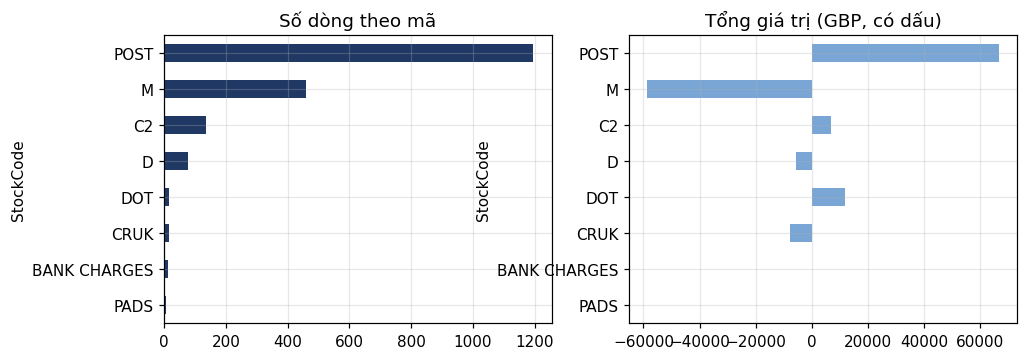

Mã dạng lạ nhưng KHÔNG nằm trong NON_PRODUCT_CODES (cần xem tay): ['PADS']


In [9]:
ident = df.drop_duplicates()
ident = ident[ident["CustomerID"].notna()]
is_product_like = ident["StockCode"].str.match(r"^\d{5}[A-Za-z]{0,2}$")
odd = ident[~is_product_like].copy()
odd["LineTotal"] = odd["Quantity"] * odd["UnitPrice"]
codes = (odd.groupby("StockCode")
            .agg(số_dòng=("Quantity", "size"),
                 mô_tả=("Description", lambda s: s.dropna().mode().iloc[0] if s.notna().any() else None),
                 tổng_giá_trị=("LineTotal", "sum"),
                 đơn_giá_trung_vị=("UnitPrice", "median"))
            .sort_values("số_dòng", ascending=False))
display(codes)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
codes["số_dòng"].plot.barh(ax=ax[0], color="#1F3864"); ax[0].set_title("Số dòng theo mã"); ax[0].invert_yaxis()
codes["tổng_giá_trị"].plot.barh(ax=ax[1], color="#7aa6d6"); ax[1].set_title("Tổng giá trị (GBP, có dấu)"); ax[1].invert_yaxis()
savefig("eda_nonproduct_codes.png"); plt.show()

not_in_list = sorted(set(codes.index) - set(NON_PRODUCT_CODES))
print("Mã dạng lạ nhưng KHÔNG nằm trong NON_PRODUCT_CODES (cần xem tay):", not_in_list)

**Quyết định:** các mã `POST`, `DOT` (phí vận chuyển/bưu điện), `M` (nhập tay), `C2` (carriage), `D` (chiết khấu), `CRUK` (hoa hồng), `BANK CHARGES` (phí ngân hàng) là **phí/điều chỉnh chứ không phải sản phẩm** → loại khỏi cả `sales_df` và `cancel_df`. Lý do: nếu giữ, đặc trưng `NUniqueProducts` bị lệch (nhiều khách "mua" POST, một mã không phải hàng hóa), `Monetary` lẫn cả phí vận chuyển và các khoản chiết khấu âm, và `CancelRate` bị nhiễu bởi hóa đơn chỉ chứa chiết khấu `D`.

`PADS` (đệm gối, đơn giá 0,001) trông lạ nhưng là sản phẩm thật nên **giữ lại** (giá trị không đáng kể). Các mã lạ khác (`AMAZONFEE`, `S`, `B`, `gift_0001_*`, `DCGS*`...) chỉ xuất hiện ở dòng thiếu `CustomerID` nên đã bị loại từ trước; danh sách `NON_PRODUCT_CODES` vì vậy chỉ gồm các mã thực sự gặp ở dòng có `CustomerID`.

### B6. Kiểu dữ liệu và định dạng

In [10]:
print(df.dtypes.to_string())
print()
print("InvoiceDate hợp lệ:", df["InvoiceDate"].notna().all(), "| không có dòng nào ngoài khoảng", df["InvoiceDate"].min().date(), "-", df["InvoiceDate"].max().date())
print("Quantity là số nguyên:", pd.api.types.is_integer_dtype(df["Quantity"]), "| UnitPrice là số thực:", pd.api.types.is_float_dtype(df["UnitPrice"]))
print()
print("Giá trị Country lạ:", [c for c in df["Country"].unique() if c in ("Unspecified", "European Community")])
print("Dòng có khoảng trắng thừa ở StockCode:", (df["StockCode"] != df["StockCode"].str.strip()).sum())

InvoiceNo                 str
StockCode                 str
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID              Int64
Country                   str

InvoiceDate hợp lệ: True | không có dòng nào ngoài khoảng 2010-12-01 - 2011-12-09
Quantity là số nguyên: True | UnitPrice là số thực: True

Giá trị Country lạ: ['Unspecified', 'European Community']
Dòng có khoảng trắng thừa ở StockCode: 0


**Nhận xét:** `load_raw()` đã ép `InvoiceNo`/`StockCode` thành chuỗi, `CustomerID` thành `Int64` (có thể thiếu), `InvoiceDate` thành datetime; không phát hiện lỗi định dạng ngày hay kiểu số. `Country` có hai giá trị đặc biệt (`Unspecified`, `European Community`); chỉ ảnh hưởng nếu dùng quốc gia làm đặc trưng (Thành phụ trách EDA quốc gia), không xử lý ở bước làm sạch.

### B7. Ngoại lệ về `Quantity`, `UnitPrice`, giá trị dòng

Để không dùng thông tin từ giai đoạn kiểm chứng, phân tích ngoại lệ dưới đây **chỉ lấy giao dịch trước `CUTOFF`** (giai đoạn quan sát) sau khi đã làm sạch cơ bản.

Giai đoạn quan sát (trước 2011-09-09): 231,630 dòng bán, 3,360 khách


,count,mean,std,min,50%,90%,99%,99.9%,max
Quantity,"231,630.00",13.74,160.79,1.00,6.00,24.00,144.00,576.00,"74,215.00"
UnitPrice,"231,630.00",2.96,4.88,0.00,1.95,6.75,12.75,39.95,649.50
LineTotal,"231,630.00",23.03,193.11,0.00,12.75,37.50,207.36,838.80,"77,183.60"


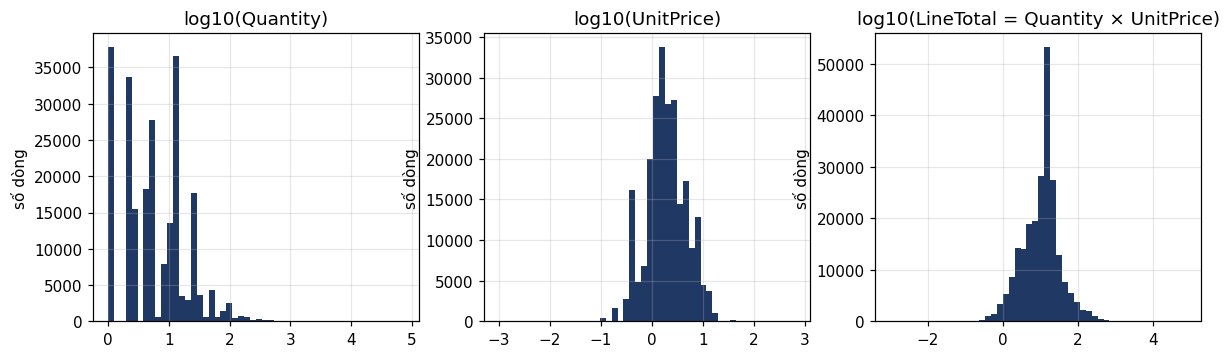

In [11]:
sales_tmp, cancel_tmp, _ = clean_transactions(df)
obs = sales_tmp[sales_tmp["InvoiceDate"] < CUTOFF]
print(f"Giai đoạn quan sát (trước {CUTOFF}): {len(obs):,} dòng bán, {obs['CustomerID'].nunique():,} khách")
stats = obs[["Quantity", "UnitPrice", "LineTotal"]].describe(percentiles=[.5, .9, .99, .999]).T
display(stats)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(np.log10(obs["Quantity"]), bins=50, color="#1F3864"); ax[0].set_title("log10(Quantity)")
ax[1].hist(np.log10(obs["UnitPrice"]), bins=50, color="#1F3864"); ax[1].set_title("log10(UnitPrice)")
ax[2].hist(np.log10(obs["LineTotal"]), bins=50, color="#1F3864"); ax[2].set_title("log10(LineTotal = Quantity × UnitPrice)")
for a in ax: a.set_ylabel("số dòng")
savefig("eda_qty_price_distribution.png"); plt.show()

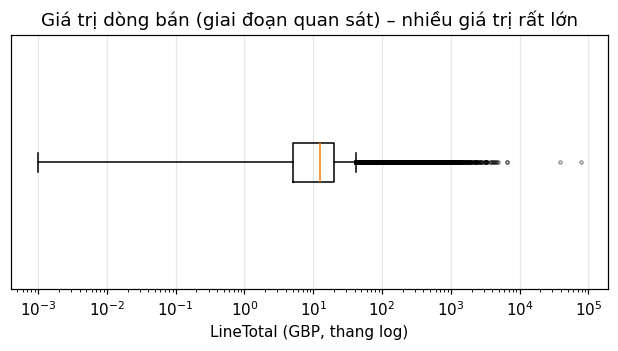

10 dòng có giá trị lớn nhất:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,LineTotal
36375,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346,"77,183.60"
152958,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,15098,"38,970.00"
32071,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,15749,"6,539.40"
107761,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,15749,"6,539.40"
32069,540815,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.55,15749,"4,921.50"
107757,550461,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.40,15749,"4,632.00"
32131,540818,48185,DOORMAT FAIRY CAKE,670,6.75,15749,"4,522.50"
168907,558526,23173,REGENCY TEAPOT ROSES,540,8.15,17949,"4,401.00"
107759,550461,48185,DOORMAT FAIRY CAKE,670,6.35,15749,"4,254.50"
200972,562439,84879,ASSORTED COLOUR BIRD ORNAMENT,2880,1.45,12931,"4,176.00"


Ví dụ: khách 12346 – một đơn rất lớn, sau đó bị hủy toàn bộ:


,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate
61619,541431,23166,74215,1.04,2011-01-18 10:01:00
61624,C541433,23166,-74215,1.04,2011-01-18 10:17:00


In [12]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.boxplot(obs["LineTotal"], vert=False, showfliers=True, flierprops={"markersize": 2, "alpha": .4})
ax.set_xscale("log"); ax.set_xlabel("LineTotal (GBP, thang log)"); ax.set_yticks([])
ax.set_title("Giá trị dòng bán (giai đoạn quan sát) – nhiều giá trị rất lớn")
savefig("eda_line_total_outliers.png"); plt.show()

print("10 dòng có giá trị lớn nhất:")
display(obs.nlargest(10, "LineTotal")[["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "LineTotal"]])

print("Ví dụ: khách 12346 – một đơn rất lớn, sau đó bị hủy toàn bộ:")
display(df[df["CustomerID"] == 12346][["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "InvoiceDate"]])

**Nhận xét và quyết định**

- `Quantity`, `UnitPrice` và `LineTotal` đều **lệch phải rất mạnh** (đuôi dài; nhìn thang log mới thấy hình dạng): đa số dòng nhỏ (phân vị 99,9% của `Quantity` chỉ vài trăm đơn vị) nhưng có một số ít dòng cực lớn (tối đa hàng chục nghìn đơn vị hoặc đơn giá hàng trăm bảng), nhiều khả năng liên quan khách mua sỉ.
- **Quyết định: không xóa ngoại lệ ở mức dòng.** Lý do: (1) đây là hành vi thật của nhóm khách sỉ, một phần mục tiêu của phân khúc là nhận diện họ; (2) không có căn cứ nghiệp vụ để coi là lỗi nhập liệu; (3) cắt theo ngưỡng thống kê tính từ dữ liệu có nguy cơ làm méo kết quả và phải chọn ngưỡng tùy ý. Thay vào đó xử lý ở **mức khách hàng** (tuần 2): `log1p` để nén đuôi, xem xét gắn cờ khách ngoại lệ; DBSCAN có thể tự tách các khách này thành nhiễu, còn K-Means nhạy với ngoại lệ nên sẽ được phân tích ảnh hưởng lên tâm cụm.
- **Lưu ý cho tuần 2 (Huy):** có đơn lớn bị hủy ngay sau đó (ví dụ khách 12346: mua 74.215 đơn vị rồi hủy đúng số lượng đó 16 phút sau). Nếu `Monetary` chỉ cộng giao dịch bán thì khách này có chi tiêu rất lớn dù chi tiêu thực bằng 0. Cần quyết định có cộng giá trị hóa đơn hủy vào `Monetary` (chi tiêu ròng) hay không và nêu lý do trong notebook 02.

## C. Hàm `clean_transactions()` và log làm sạch

Logic cài đặt trong `src/cleaning.py` (có docstring, thứ tự bước đã nêu ở trên). Số dòng bị loại được **đếm tuần tự** (một dòng chỉ tính vào lý do đầu tiên nó dính); bảng bên dưới cho thấy thêm số dòng thuộc từng lý do tính độc lập để thấy mức chồng lấn.

,số dòng
rows_raw,541909
removed_duplicates,5268
removed_missing_customer,135037
cancel_rows_split,8872
removed_nonpositive_quantity,0
removed_nonpositive_price,40
removed_nonproduct_sales,1539
removed_nonproduct_cancel,366
rows_sales,391153
rows_cancel,8506


,"số dòng (tính độc lập, có chồng lấn)"
Dòng trùng lặp hoàn toàn,5268
Thiếu CustomerID,135080
Hóa đơn hủy (C...),9288
Bán: Quantity <= 0,1336
Bán: UnitPrice <= 0,2517
StockCode không phải sản phẩm,2812


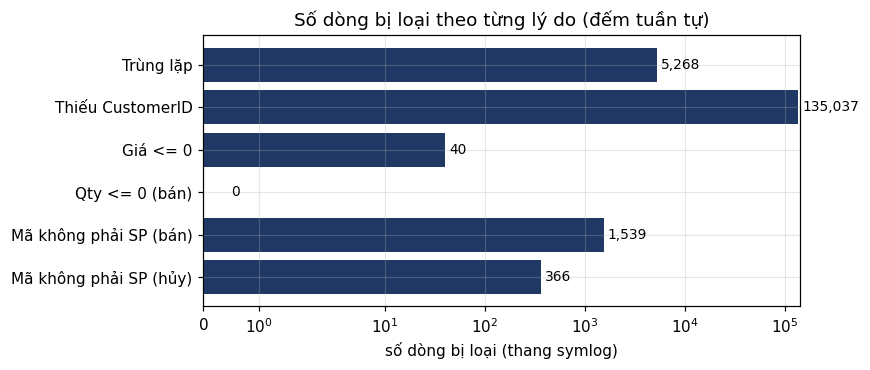

Đã lưu log: reports/tables/cleaning_log.csv


In [13]:
sales_df, cancel_df, log = clean_transactions(df)
log_df = pd.DataFrame({"số dòng": log})
display(log_df)

is_c = df["InvoiceNo"].str.startswith("C")
independent = pd.Series({
    "Dòng trùng lặp hoàn toàn": df.duplicated().sum(),
    "Thiếu CustomerID": df["CustomerID"].isna().sum(),
    "Hóa đơn hủy (C...)": is_c.sum(),
    "Bán: Quantity <= 0": ((~is_c) & (df["Quantity"] <= 0)).sum(),
    "Bán: UnitPrice <= 0": ((~is_c) & (df["UnitPrice"] <= 0)).sum(),
    "StockCode không phải sản phẩm": df["StockCode"].isin(NON_PRODUCT_CODES).sum(),
}, name="số dòng (tính độc lập, có chồng lấn)")
display(independent.to_frame())

reasons = {
    "Trùng lặp": log["removed_duplicates"],
    "Thiếu CustomerID": log["removed_missing_customer"],
    "Giá <= 0": log["removed_nonpositive_price"],
    "Qty <= 0 (bán)": log["removed_nonpositive_quantity"],
    "Mã không phải SP (bán)": log["removed_nonproduct_sales"],
    "Mã không phải SP (hủy)": log["removed_nonproduct_cancel"],
}
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(list(reasons), list(reasons.values()), color="#1F3864"); ax.invert_yaxis()
ax.set_xscale("symlog"); ax.set_xlabel("số dòng bị loại (thang symlog)")
ax.set_title("Số dòng bị loại theo từng lý do (đếm tuần tự)")
for i, v in enumerate(reasons.values()):
    ax.text(v * 1.1 + 0.5, i, f"{v:,}", va="center", fontsize=9)
savefig("eda_removed_rows_by_reason.png"); plt.show()

path = save_cleaning_log(log)
print("Đã lưu log:", path.relative_to(ROOT))

In [14]:
# Kiểm tra tự động các bất biến sau làm sạch
assert sales_df["CustomerID"].notna().all() and cancel_df["CustomerID"].notna().all()
assert not sales_df["InvoiceNo"].str.startswith("C").any()
assert cancel_df["InvoiceNo"].str.startswith("C").all()
assert (sales_df["Quantity"] > 0).all() and (sales_df["UnitPrice"] > 0).all()
assert (cancel_df["Quantity"] < 0).all()
assert not sales_df["StockCode"].isin(NON_PRODUCT_CODES).any()
assert not sales_df.duplicated().any()
# Đối chiếu: tổng số dòng đầu vào = các dòng bị loại + dòng còn lại
removed = (log["removed_duplicates"] + log["removed_missing_customer"] + log["removed_nonpositive_quantity"]
           + log["removed_nonpositive_price"] + log["removed_nonproduct_sales"] + log["removed_nonproduct_cancel"])
assert log["rows_raw"] == removed + log["rows_sales"] + log["rows_cancel"]
print("Mọi kiểm tra đều đạt.")

Mọi kiểm tra đều đạt.


## D. Tóm tắt dữ liệu sau làm sạch

In [15]:
final = pd.Series({
    "Dòng bán (sales_df)": len(sales_df),
    "Dòng hóa đơn hủy (cancel_df)": len(cancel_df),
    "Số khách có giao dịch bán": sales_df["CustomerID"].nunique(),
    "Số khách có hóa đơn hủy": cancel_df["CustomerID"].nunique(),
    "Số hóa đơn bán": sales_df["InvoiceNo"].nunique(),
    "Số mã sản phẩm": sales_df["StockCode"].nunique(),
    "Số quốc gia": sales_df["Country"].nunique(),
})
display(final.to_frame("giá trị"))
print("Khoảng thời gian dữ liệu bán:", sales_df["InvoiceDate"].min(), "->", sales_df["InvoiceDate"].max())

,giá trị
Dòng bán (sales_df),391153
Dòng hóa đơn hủy (cancel_df),8506
Số khách có giao dịch bán,4334
Số khách có hóa đơn hủy,1534
Số hóa đơn bán,18402
Số mã sản phẩm,3660
Số quốc gia,37


Khoảng thời gian dữ liệu bán: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00


### Kết luận và khẳng định kiểm soát leakage

- Sau làm sạch còn khoảng 391 nghìn dòng bán của khoảng 4.334 khách (số chính xác ở bảng trên), cộng với `cancel_df` để tính `CancelRate`.
- **Bước này chưa dùng bất kỳ thông tin nào từ giai đoạn kiểm chứng để ra quyết định.** Cụ thể: (1) mọi quy tắc làm sạch là quy tắc logic/định dạng (thiếu mã khách, trùng lặp, hóa đơn hủy, số lượng/giá không dương, mã phi sản phẩm), không có ngưỡng thống kê nào tính từ dữ liệu; (2) phần B1–B6 chỉ đếm và mô tả trên toàn bộ dữ liệu để biết quy mô vấn đề, không làm thay đổi quy tắc; (3) phân tích ngoại lệ ở mục B7 chỉ dùng giao dịch trước `CUTOFF`; (4) chưa tạo bất kỳ nhãn hay đặc trưng nào, việc chia theo `CUTOFF` và tính RFM thuộc tuần 2.
- **Hạn chế đã nhận diện** (đưa vào chương hạn chế): ~24,9% dòng không có `CustomerID` nên không phân khúc được; dữ liệu một công ty ở Anh, khoảng 91% dòng thuộc United Kingdom; chỉ ~13 tháng nên mùa vụ chưa lặp lại.
